In [1]:
import numpy as np
import os
import sys
from volta.paths import RESULT_ROOT
from volta.plotting import *
# 1. Define where to look
folder_name = f"{RESULT_ROOT}/Progress/data"
file_name = "CoMandSwTrackingExperimennt_0.npz"

full_path = os.path.join(folder_name, file_name)

# 2. Load the file
try:
    loaded_data = np.load(full_path)
    print(f"Successfully loaded {full_path}")
    print(f"Loaded {len(loaded_data['timestamp'])} timesteps.")

except FileNotFoundError:
    print(f"Error: The file {full_path} was not found.")

Successfully loaded /home/tanawatp/Documents/Thesis_simulation/M_result/Progress/data/CoMandSwTrackingExperimennt_0.npz
Loaded 95631 timesteps.


In [ ]:
print("Keys found in file:", loaded_data.files)
# 3. Extract the data back into variables
# Note: Use the same string keys used in the save function
timestamp:np.ndarray                = loaded_data['timestamp']
desired_com_data:np.ndarray         = loaded_data['desired_com']
desired_sw_leg_data:np.ndarray      = loaded_data['desired_sw_leg']
desired_foot_wrench_data:np.ndarray = loaded_data['desired_foot_wrenches']
fz_bounds_data:np.ndarray           = loaded_data['fz_boundaries']
walking_phase_data:np.ndarray      = loaded_data['walking_phase']
CoM_states_in_st_data:np.ndarray    = loaded_data['CoM_state_in_st']
sw_states_in_st_data:np.ndarray     = loaded_data['sw_state_in_st']
torque_command_data:np.ndarray      = loaded_data['torque_command_data']
# 4. (Optional) Close the file handle if you are done
loaded_data.close()
start_time = 0.0
end_time = 9.0
plot_interval = (start_time,end_time)
#Extract datas
CoM_orientation_in_st = CoM_states_in_st_data[0:3]
CoM_position_in_st = CoM_states_in_st_data[3:6]
CoM_angular_velocity_in_st = CoM_states_in_st_data[6:9]
CoM_linear_velocity_in_st = CoM_states_in_st_data[9:12]

sw_leg_orientation_in_st = sw_states_in_st_data[0:3]
sw_leg_position_in_st = sw_states_in_st_data[3:6]
sw_leg_angular_velocity_in_st = sw_states_in_st_data[6:9]
sw_leg_linear_velocity_in_st = sw_states_in_st_data[9:12]

desired_CoM_position_in_st = desired_com_data[0:3]
desired_CoM_velocity_in_st = desired_com_data[3:6]

desired_sw_leg_position_in_st = desired_sw_leg_data[0:3]
desired_sw_leg_velocity_in_st = desired_sw_leg_data[3:6]

save_folder = f"{RESULT_ROOT}/Pics"

Keys found in file: ['timestamp', 'desired_com', 'desired_sw_leg', 'desired_foot_wrenchs', 'fz_boundaries', 'walking_phase', 'CoM_state_in_st', 'sw_state_in_st', 'torque_command_data']


Saved to: /home/tanawatp/Documents/Thesis_simulation/M_result/Pics/com_position_tracking_(t=0.0s_to_9.0s).pdf


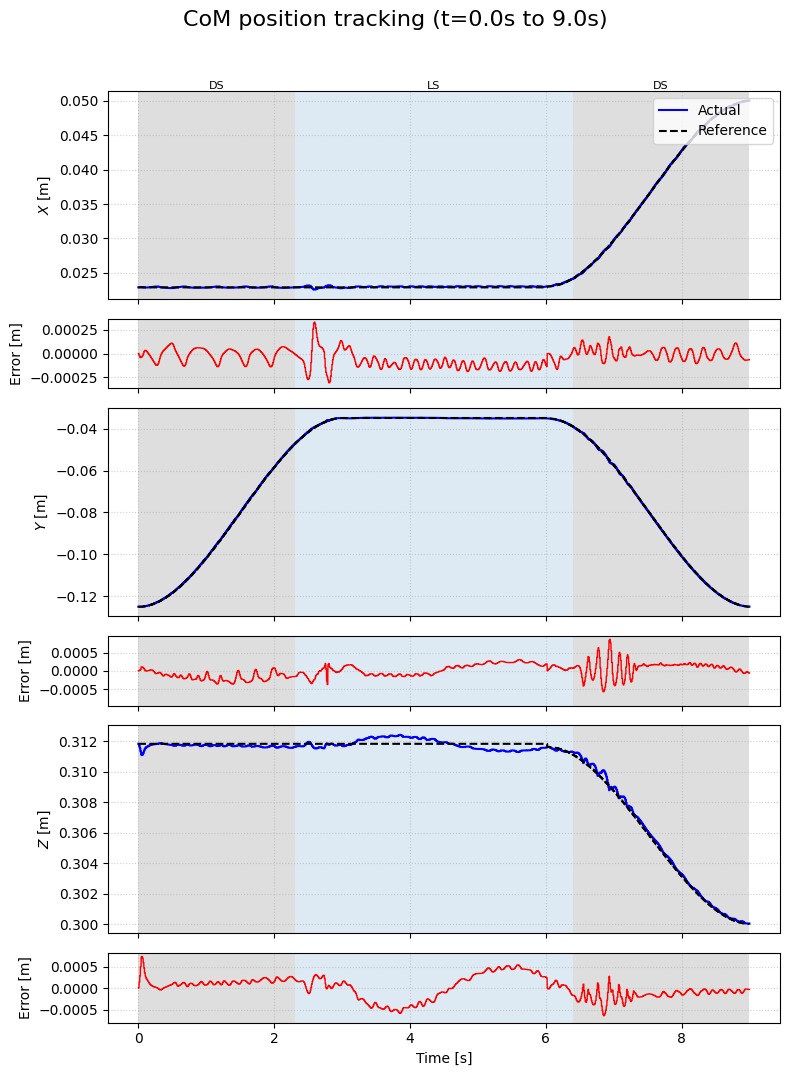

In [3]:
PlotTracking(
    time_log=timestamp, 
    ref_data=desired_CoM_position_in_st, 
    act_data=CoM_position_in_st, 
    title="CoM position tracking",
    phase_codes=walking_phase_data[0], 
    plot_interval=plot_interval,
    save_folder=save_folder
)

Saved to: /home/tanawatp/Documents/Thesis_simulation/M_result/Pics/com_velocities_tracking_(t=0.0s_to_9.0s).pdf


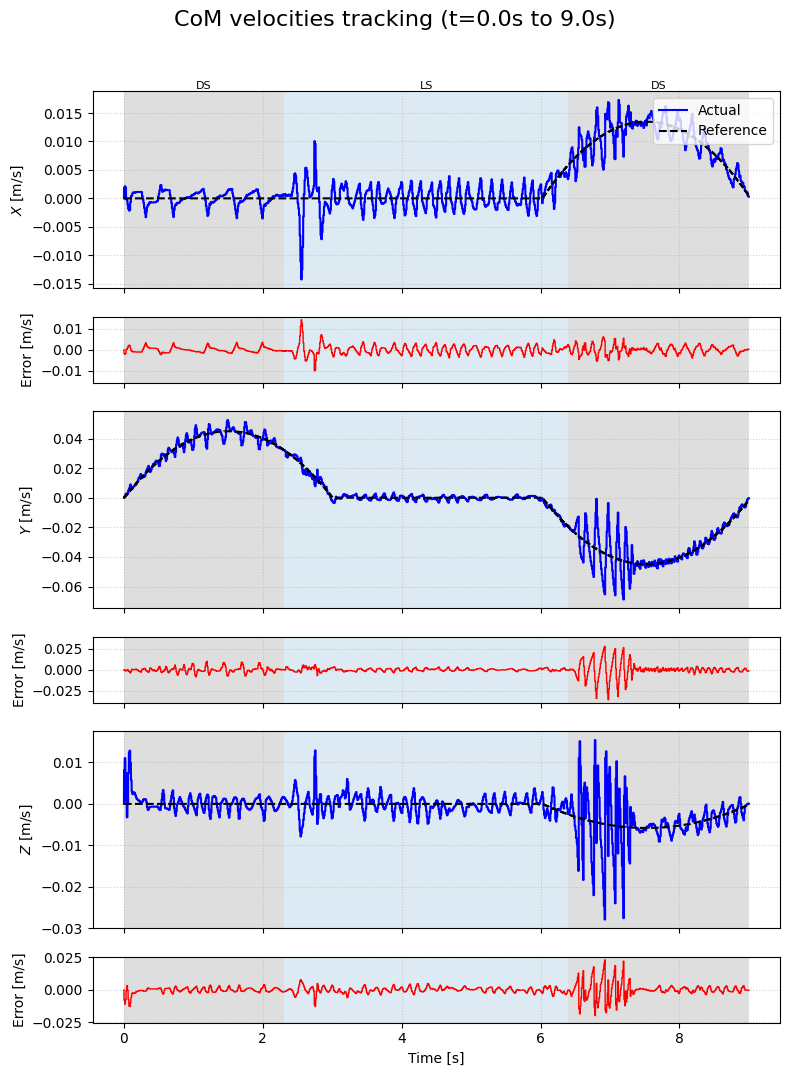

In [4]:
PlotTracking(
    time_log=timestamp, 
    ref_data=desired_CoM_velocity_in_st, 
    act_data=CoM_linear_velocity_in_st, 
    phase_codes=walking_phase_data[0], 
    title="CoM velocities tracking",
    unit="m/s",
    plot_interval=plot_interval,
    save_folder=save_folder 
)

Saved to: /home/tanawatp/Documents/Thesis_simulation/M_result/Pics/com_orientation_tracking_(t=0.0s_to_9.0s).pdf


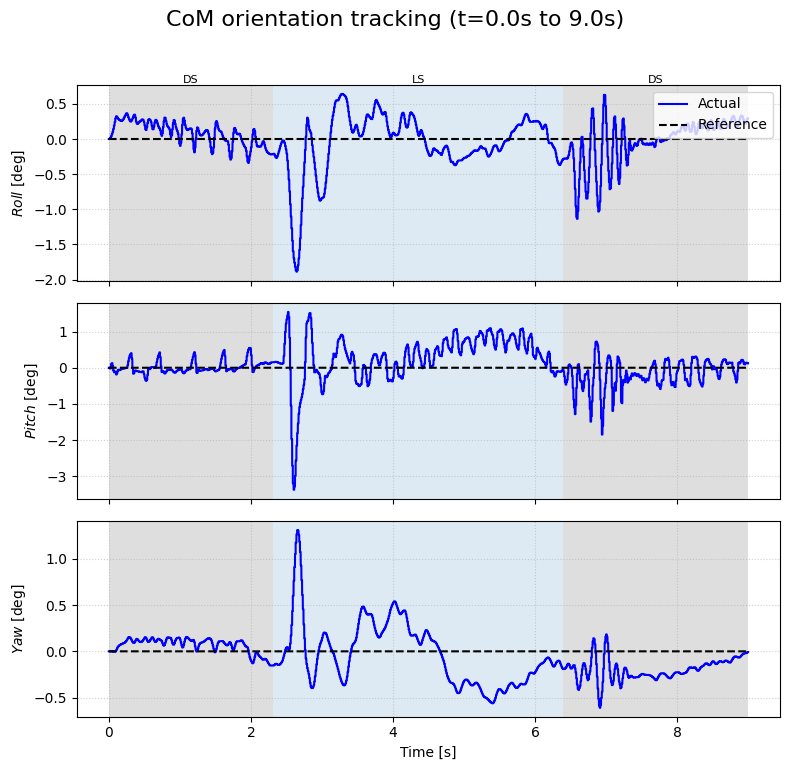

In [5]:
PlotTracking(
    time_log=timestamp, 
    ref_data=np.zeros([3,len(timestamp)]), 
    act_data=CoM_orientation_in_st*180.0/np.pi, 
    phase_codes=walking_phase_data[0], 
    dim_labels=['Roll','Pitch','Yaw'],
    title="CoM orientation tracking",
    unit="deg",
    show_error=False,
    plot_interval=plot_interval,
    save_folder=save_folder
)

Saved to: /home/tanawatp/Documents/Thesis_simulation/M_result/Pics/swing_leg_position_tracking_(t=0.0s_to_9.0s).pdf


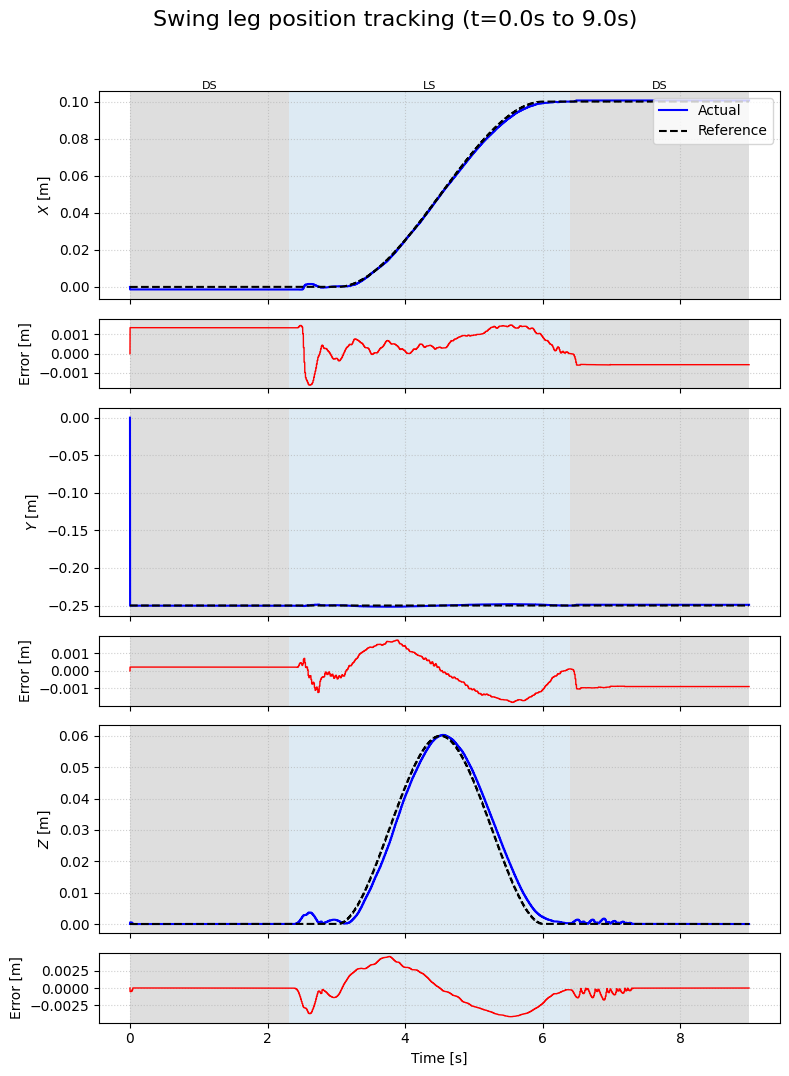

In [6]:
PlotTracking(
    time_log=timestamp, 
    ref_data=desired_sw_leg_position_in_st, 
    act_data=sw_leg_position_in_st,
    phase_codes=walking_phase_data[0], 
    title="Swing leg position tracking",
    plot_interval=plot_interval,
    save_folder=save_folder 
)

Saved to: /home/tanawatp/Documents/Thesis_simulation/M_result/Pics/swing_leg_velocity_tracking_(t=0.0s_to_9.0s).pdf


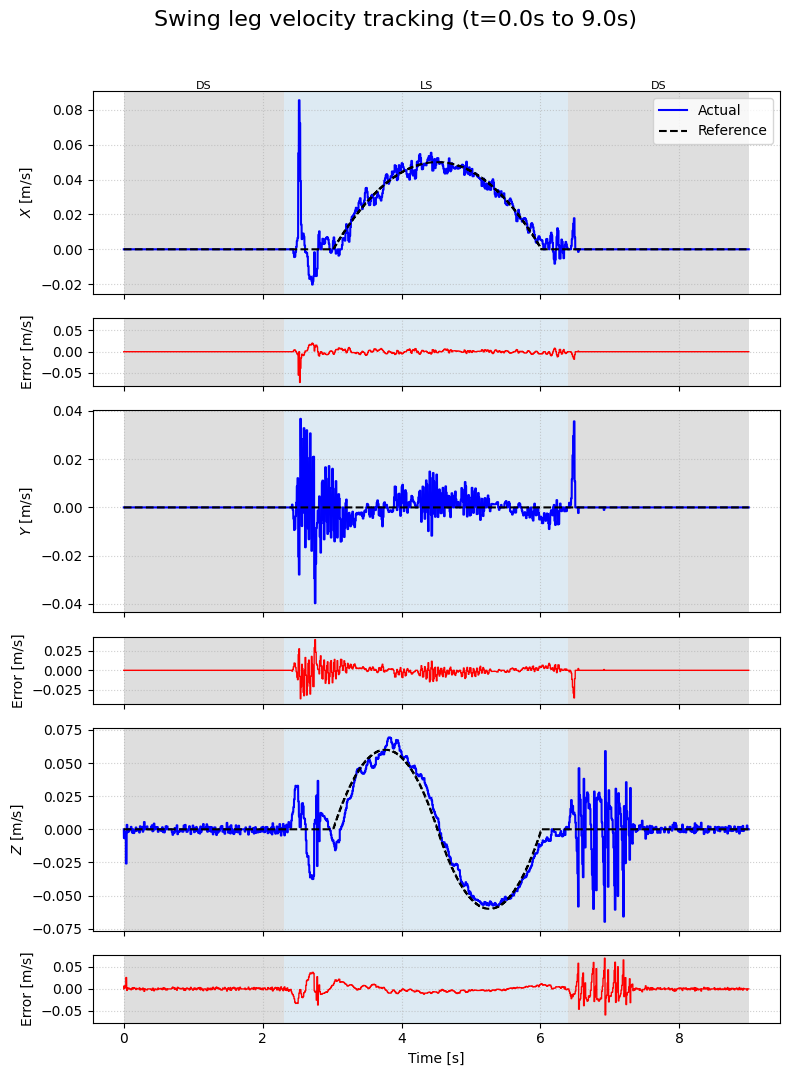

In [7]:
PlotTracking(
    time_log=timestamp, 
    ref_data=desired_sw_leg_velocity_in_st, 
    act_data=sw_leg_linear_velocity_in_st, 
    phase_codes=walking_phase_data[0], 
    title="Swing leg velocity tracking",
    unit="m/s",
    plot_interval=plot_interval,
    save_folder=save_folder
)

Saved to: /home/tanawatp/Documents/Thesis_simulation/M_result/Pics/swing_leg_orientation_tracking_(t=0.0s_to_9.0s).pdf


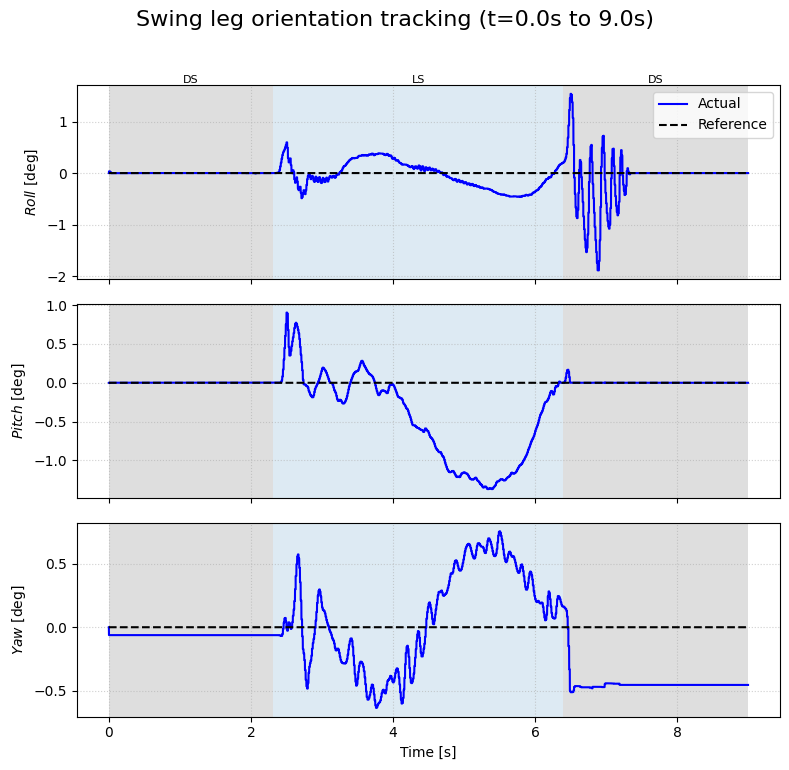

In [8]:
PlotTracking(
    time_log=timestamp, 
    ref_data=np.zeros([3,len(timestamp)]), 
    act_data=sw_leg_orientation_in_st*180.0/np.pi, 
    phase_codes=walking_phase_data[0], 
    dim_labels=['Roll','Pitch','Yaw'],
    title="Swing leg orientation tracking",
    unit="deg",
    show_error=False,
    plot_interval=plot_interval,
    save_folder=save_folder
)

In [9]:
import matplotlib.pyplot as plt
import numpy as np

def PlotGRF(
    time_data, 
    ref_data,
    actual_data, 
    bounds_data, # Renamed for clarity (fz_boundaries_log)
    time_interval=None, # Replaces 'boundary' tuple
    components_to_plot=[5] # Default to Fz (Index 5), can add 3, 4 for Fx, Fy
):
    """
    Plots Ground Reaction Forces (GRF) with constraints for Thesis.
    Separates Left and Right feet for clarity.
    """
    
    # --- 2. Robust Time Slicing ---
    if time_interval:
        t_start, t_end = time_interval
        idx_start = np.searchsorted(time_data, t_start)
        idx_end = np.searchsorted(time_data, t_end)
    else:
        idx_start, idx_end = 0, len(time_data)

    # Slice all arrays
    t = time_data[idx_start:idx_end]
    grf = actual_data[:, idx_start:idx_end]
    des = ref_data[:, idx_start:idx_end]
    bounds = bounds_data[:, idx_start:idx_end]

    # --- 3. Plotting Setup ---
    # Define labels for indices 0-5
    labels = ["Moment X", "Moment Y", "Moment Z", "Force X", "Force Y", "Force Z"]
    units  = ["Nm", "Nm", "Nm", "N", "N", "N"]

    for idx in components_to_plot:
        fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
        
        # --- LEFT FOOT Plot (Top) ---
        ax_L = axes[0]
        # Actual & Desired
        ax_L.plot(t, des[idx, :], 'k--', linewidth=1.5, label='Desired')
        ax_L.plot(t, grf[idx, :], 'b-', linewidth=1.5, label='Actual')
        
        # Constraints (Only applicable for Fz / Index 5 based on your code structure)
        if idx == 5: 
            # Assuming bounds structure: [Min_L, Max_L, Min_R, Max_R, ...]
            # Use fill_between for a professional "Safe Region" look
            ax_L.fill_between(t, bounds[0, :], bounds[1, :], 
                              color='green', alpha=0.15, label='Constraint Bounds')
            
        ax_L.set_ylabel(f"Left {labels[idx]} [{units[idx]}]")
        ax_L.grid(True, linestyle=':', alpha=0.6)
        ax_L.legend(loc='upper right')
        
        # --- RIGHT FOOT Plot (Bottom) ---
        ax_R = axes[1]
        # Note: Right foot indices are shifted by 6 (e.g., Fz Right is index 11)
        ax_R.plot(t, des[idx+6, :], 'k--', linewidth=1.5, label='Desired')
        ax_R.plot(t, grf[idx+6, :], 'r-', linewidth=1.5, label='Actual') # Red for Right foot convention
        
        if idx == 5:
            # Bounds for Right foot (Indices 2 and 3 based on your code)
            ax_R.fill_between(t, bounds[2, :], bounds[3, :], 
                              color='green', alpha=0.15, label='Constraint Bounds')

        ax_R.set_ylabel(f"Right {labels[idx]} [{units[idx]}]")
        ax_R.grid(True, linestyle=':', alpha=0.6)
        ax_R.legend(loc='upper right')
        
        # Formatting
        axes[-1].set_xlabel("Time [s]")
        fig.suptitle(f"{labels[idx]} Tracking with Constraints", fontsize=14, y=0.95)
        plt.tight_layout()
        plt.show()

